# Demonstração do repositório: de Heston ao hedge

**Objetivo.** Entender o que cada módulo científico faz, aprender a chamar suas funções e interpretar as saídas. Este notebook é uma **demo de código**, não um experimento conclusivo de pesquisa.

**Como usar:** execute as células de cima para baixo (`Run All`), altere uma entrada e reexecute a célula para ver o efeito. Os gráficos aparecem aqui mesmo, logo após o código que os produziu. O notebook chama diretamente `heston.py`, `portfolio.py`, `pricing.py`, `volatility.py` e `hedging.py`: **não há uma segunda implementação financeira escondida aqui**.

| Módulo | Pergunta que responde |
|:--|:--|
| `heston.py` | Quais preços e variâncias podem ocorrer? |
| `portfolio.py` | Quais contratos temos e quanto pagam no vencimento? |
| `pricing.py` | Quanto vale uma opção **hoje**? Como o valor reage aos fatores de risco? |
| `volatility.py` | Que volatilidade Black–Scholes reproduz o preço Heston? |
| `hedging.py` | Como evoluem a carteira, o caixa, as posições e o P&L ao negociar? |

Os scripts `simulate.py` e `evaluate.py` apenas coordenam experimentos completos. Veremos como executá-los ao final.

> **Atenção:** usaremos poucos caminhos e parâmetros ilustrativos. Não tire conclusões estatísticas sobre desempenho, Q95 ou CVaR95 usando esta demo.

## 0. Ambiente e parâmetros

O notebook fica **na raiz do repositório**, ao lado dos `.py` e de `config.json`. Precisamos de NumPy, SciPy e Matplotlib. No JupyterLab ou VS Code, selecione o kernel do `.venv` do projeto.

A primeira célula só importa as funções existentes.

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from heston import HestonParams, MarketDynamics, simulate_heston
from portfolio import EuropeanOption, OptionBook, sample_books, expiry_cashflows
from pricing import (black_scholes_price, heston_price, heston_greeks,
                     heston_greeks_batch, price_book)
from volatility import (implied_volatility, heston_volatility_surface,
                        build_volatility_lookup)
from hedging import value_book_paths, simulate_hedge, summarize_hedge

config = json.loads(Path("config.json").read_text(encoding="utf-8"))
config.keys()

dict_keys(['simulation', 'heston', 'books', 'volatility_surface', 'hedging'])

Em `config.json`, os blocos `heston` e `simulation` definem a simulação principal; `hedging` contém os parâmetros da avaliação financeira. **Aqui reutilizaremos esses valores, mas com uma amostra menor para facilitar a exploração.**

In [3]:
config["heston"], config["simulation"]["spot0"], config["hedging"]["fixed_cost"]

({'kappa': 2.0, 'theta': 0.04, 'xi': 0.4, 'rho': -0.7, 'v0': 0.04}, 100.0, 0.5)

## 1. `heston.py` — construir um cenário de mercado

### 1.1. Parâmetros do modelo e medidas P e Q

Em Heston, além do preço $S_t$, modelamos a **variância instantânea** $v_t$. A volatilidade instantânea é $\sqrt{v_t}$; se $v_t=0{,}04$, a volatilidade é $20\%$ em termos anuais.

$$\begin{aligned}
dS_t&=\mu S_t\,dt+\sqrt{v_t}S_t\,dW_t^S,\\
dv_t&=\kappa(\theta-v_t)dt+\xi\sqrt{v_t}\,dW_t^v,\qquad d\langle W^S,W^v\rangle_t=\rho\,dt.
\end{aligned}$$

Usaremos **P para trajetórias de risco** e **Q para preços teóricos**. O código exige essa distinção explicitamente. Neste piloto, alguns parâmetros coincidem numericamente entre P e Q, mas isso **não** estabelece uma relação calibrada entre as medidas nem um prêmio de risco de volatilidade.

In [4]:
params_q = HestonParams(**config["heston"])
params_p = HestonParams(**config["hedging"]["physical_heston"])

market_q = MarketDynamics(
    measure="Q",
    spot0=config["simulation"]["spot0"],
    risk_free_rate=config["simulation"]["risk_free_rate"],
    dividend_yield=config["simulation"]["dividend_yield"],
)
market_p = MarketDynamics(
    measure="P",
    spot0=market_q.spot0,
    risk_free_rate=market_q.risk_free_rate,
    dividend_yield=market_q.dividend_yield,
    physical_total_return=config["hedging"]["physical_total_return"],
)

print("Volatilidade inicial:", f"{np.sqrt(params_p.v0):.1%}")
print("Correlação rho:", params_p.rho)
print("Razão de Feller:", params_p.feller_ratio)
print("Drift do preço em P:", f"{market_p.spot_drift:.1%}")
print("Drift do preço em Q:", f"{market_q.spot_drift:.1%}")

Volatilidade inicial: 20.0%
Correlação rho: -0.7
Razão de Feller: 0.9999999999999998
Drift do preço em P: 10.0%
Drift do preço em Q: 10.0%


### 1.2. `simulate_heston()` — simular trajetórias

**Entrada:** parâmetros Heston, descrição do mercado, quantidade de caminhos, quantidade de dias e semente aleatória. **Saída:** um objeto `HestonPaths` contendo, entre outros campos, `spot`, `variance` e `time_years`.

As matrizes `spot` e `variance` têm forma `(n_paths, n_steps + 1)`, porque o instante **0** também é armazenado.

In [5]:
N_PATHS = 12          # Pequeno de propósito: demo, não backtest estatístico
N_STEPS = 63          # 63 dias úteis
DAYS_PER_YEAR = config["simulation"]["trading_days_per_year"]

daily_paths = simulate_heston(
    params_p, market_p, n_paths=N_PATHS, n_steps=N_STEPS,
    trading_days_per_year=DAYS_PER_YEAR, seed=123,
)
days = np.arange(N_STEPS + 1)

print("Medida:", daily_paths.measure)
print("S_t shape:", daily_paths.spot.shape)
print("v_t shape:", daily_paths.variance.shape)
print("Primeiros preços do caminho 0:", np.round(daily_paths.spot[0, :5], 3))

Medida: P
S_t shape: (12, 64)
v_t shape: (12, 64)
Primeiros preços do caminho 0: [100.     98.793  99.855 103.099 104.332]


**Como interpretar:** curvas diferentes são *cenários possíveis*, não previsões pontuais. Um $\rho$ negativo significa correlação entre **choques aleatórios**, não que o preço seja obrigado a cair sempre que a variância sobe.

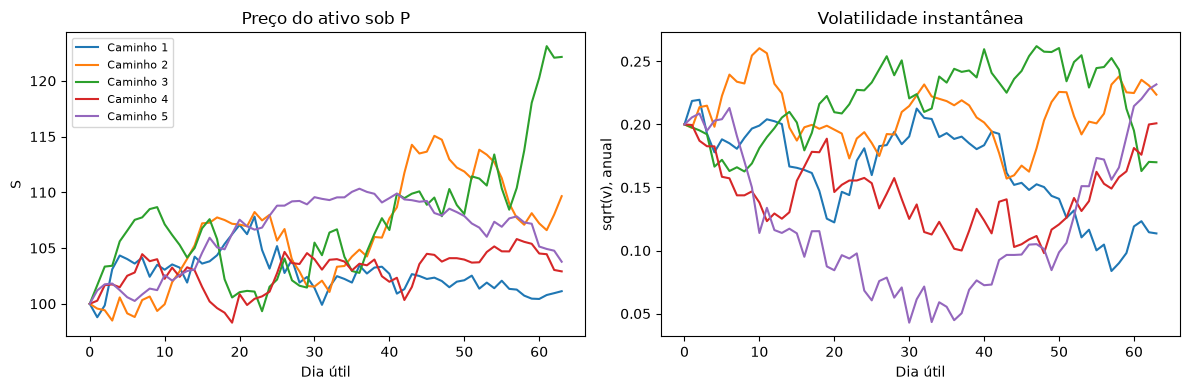

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for i in range(min(5, N_PATHS)):
    axs[0].plot(days, daily_paths.spot[i], label=f"Caminho {i+1}")
    axs[1].plot(days, np.sqrt(daily_paths.variance[i]))
axs[0].set(title="Preço do ativo sob P", xlabel="Dia útil", ylabel="S")
axs[0].legend(fontsize=8)
axs[1].set(title="Volatilidade instantânea", xlabel="Dia útil", ylabel="sqrt(v), anual")
plt.tight_layout()
plt.show()

**Checagem conceitual:** `expected_variance()` calcula $E[v_T]=\theta+(v_0-\theta)e^{-\kappa T}$ no modelo contínuo. A média de **12 caminhos** pode ser diferente por ruído amostral e discretização.

In [7]:
T = N_STEPS / DAYS_PER_YEAR
print("E[v_T] teórico:", round(params_p.expected_variance(T), 6))
print("Média simulada de v_T:", round(float(daily_paths.variance[:, -1].mean()), 6))

E[v_T] teórico: 0.04
Média simulada de v_T: 0.030278


## 2. `portfolio.py` — contratos, carteira e pagamentos

### 2.1. Construção manual com `EuropeanOption` e `OptionBook`

Uma quantidade **positiva** indica posição comprada; **negativa** indica posição vendida. `maturity_days` é contado em dias úteis a partir do dia 0. Uma call paga $\max(S_T-K,0)$ e uma put paga $\max(K-S_T,0)$, antes de considerar o sinal e o multiplicador.

Montaremos uma carteira de dois contratos com **vencimentos diferentes** para enxergar o tratamento dos pagamentos intermediários.

In [8]:
book = OptionBook(
    book_id="carteira_demo",
    contracts=(
        EuropeanOption("call_comprada", quantity=2, strike=100,
                       maturity_days=21, option_type="call"),
        EuropeanOption("put_vendida", quantity=-1, strike=95,
                       maturity_days=63, option_type="put"),
    ),
)
print("Número de contratos:", book.n_contracts)
for c in book.contracts:
    print(c)

Número de contratos: 2
EuropeanOption(contract_id='call_comprada', quantity=2, strike=100, maturity_days=21, option_type='call', multiplier=1.0)
EuropeanOption(contract_id='put_vendida', quantity=-1, strike=95, maturity_days=63, option_type='put', multiplier=1.0)


### 2.2. `expiry_cashflows()` — o que realmente entra e sai no vencimento?

**Entrada:** carteira e matriz de preços simulados. **Saída:** matriz de pagamentos **assinados**, um valor por caminho e por dia. Ainda **não** inclui prêmio, juros, compras de ações ou custo de hedge.

In [9]:
cashflows = expiry_cashflows(book, daily_paths.spot)
print("shape:", cashflows.shape)
for t in (21, 63):
    print(f"Caminho 0, dia {t}: S={daily_paths.spot[0, t]:.2f}, "
          f"pagamento={cashflows[0, t]:+.2f}")
print("Dias com pagamento potencial:", [21, 63])

shape: (12, 64)
Caminho 0, dia 21: S=106.25, pagamento=+12.49
Caminho 0, dia 63: S=101.13, pagamento=+0.00
Dias com pagamento potencial: [21, 63]


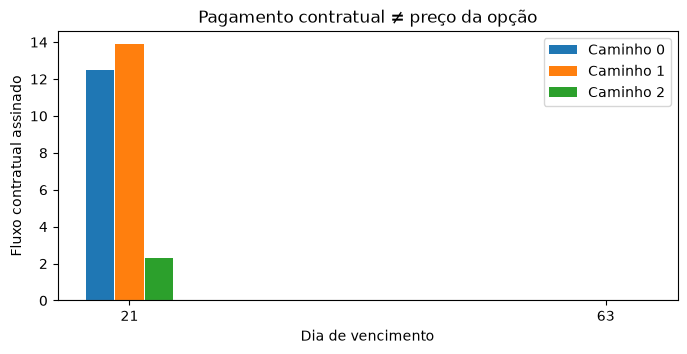

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for j, path_id in enumerate([0, 1, 2]):
    ax.bar(np.array([21, 63]) + 2.6*(j-1), cashflows[path_id, [21, 63]],
           width=2.5, label=f"Caminho {path_id}")
ax.axhline(0, color="gray", lw=0.8)
ax.set(xlabel="Dia de vencimento", ylabel="Fluxo contratual assinado",
       xticks=[21,63], title="Pagamento contratual ≠ preço da opção")
ax.legend()
plt.show()

### 2.3. `sample_books()` — gerar carteiras variáveis

Essa função gera **carteiras aleatórias reprodutíveis**, úteis para experimentos com números diferentes de contratos. **Limitação atual:** `sample_books()` sorteia apenas *calls*. A classe `EuropeanOption`, como vimos, também aceita puts criadas manualmente.

In [11]:
random_books = sample_books(
    spot_reference=market_p.spot0, n_books=4,
    sizes=(1, 3, 5), expiries_days=(21, 42, 63), seed=2026,
)
for b in random_books:
    print(f"{b.book_id}: {b.n_contracts} contrato(s) | "
          f"strikes={[round(c.strike, 1) for c in b.contracts]}")

book-0000: 5 contrato(s) | strikes=[99.0, 108.7, 104.6, 112.6, 100.5]
book-0001: 5 contrato(s) | strikes=[93.3, 97.9, 98.4, 102.8, 91.3]
book-0002: 5 contrato(s) | strikes=[103.2, 101.9, 94.6, 92.8, 99.8]
book-0003: 3 contrato(s) | strikes=[101.5, 97.6, 105.3]


## 3. `pricing.py` — valor *hoje* e sensibilidades

**Diferença essencial:** `expiry_cashflows` dá o pagamento **realizado na data de vencimento**; `heston_price` fornece um **preço teórico antes do vencimento**, calculado sob Q, condicionado a preço atual, variância atual e prazo restante.

### 3.1. `heston_price()` — preço de uma única opção

Observe os argumentos: `strike`, `maturity` (em **anos**, não dias), `option_type`, e, opcionalmente, o estado atual `spot` e `variance`.

In [12]:
tau = 63 / DAYS_PER_YEAR
p_call = heston_price(
    params_q, market_q, strike=100, maturity=tau, option_type="call"
)
p_put = heston_price(
    params_q, market_q, strike=100, maturity=tau, option_type="put"
)
print("Preço call:", round(p_call, 5))
print("Preço put:", round(p_put, 5))
print("Call - put:", round(p_call - p_put, 5))
print("S e^{-qT} - K e^{-rT}:", round(
    100*np.exp(-market_q.dividend_yield*tau) - 100*np.exp(-market_q.risk_free_rate*tau), 5))

Preço call: 5.30506
Preço put: 2.83605
Call - put: 2.46901
S e^{-qT} - K e^{-rT}: 2.46901


### 3.2. `heston_greeks()` — derivadas em relação ao estado

- **Delta:** variação do preço para pequena mudança em $S$, mantendo a variância fixa.
- **Gamma:** variação do delta para pequena mudança em $S$.
- **`variance_sensitivity`:** variação do preço para pequena mudança em $v$.
- **`initial_volatility_vega`:** derivada em relação a $\sqrt v$ inicial. **Não** é automaticamente o vega em relação à volatilidade implícita de mercado.

A versão escalar calcula essas derivadas por **diferenças finitas**, isto é, perturbando entradas e reprecificando.

In [13]:
greeks = heston_greeks(params_q, market_q, strike=100, maturity=tau)
print("Preço:", round(greeks.price, 5))
print("Delta:", round(greeks.delta, 5))
print("Gamma:", round(greeks.gamma, 6))
print("dPreço/dv:", round(greeks.variance_sensitivity, 5))
print("dPreço/dsqrt(v):", round(greeks.initial_volatility_vega, 5))

Preço: 5.30506
Delta: 0.67533
Gamma: 0.034538
dPreço/dv: 36.86985
dPreço/dsqrt(v): 14.74794


O delta é uma **aproximação local**, não uma fórmula que produz corretamente o preço para qualquer salto de $S$. O gráfico compara o preço recalculado pelo Heston com uma aproximação de primeira ordem.

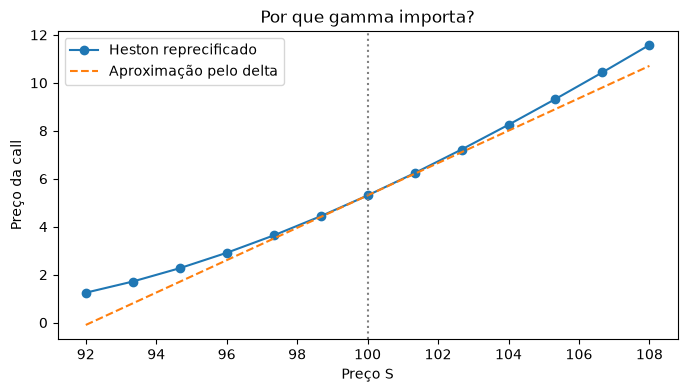

In [14]:
spots_demo = np.linspace(92, 108, 13)
prices_demo = np.array([
    heston_price(params_q, market_q, strike=100, maturity=tau, spot=float(s))
    for s in spots_demo
])
linear_approx = greeks.price + greeks.delta * (spots_demo - market_q.spot0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(spots_demo, prices_demo, "o-", label="Heston reprecificado")
ax.plot(spots_demo, linear_approx, "--", label="Aproximação pelo delta")
ax.axvline(100, color="gray", ls=":")
ax.set(xlabel="Preço S", ylabel="Preço da call", title="Por que gamma importa?")
ax.legend()
plt.show()

### 3.3. `price_book()` — valor e sensibilidades agregadas

Essa função percorre os contratos **ainda vivos**, multiplica os resultados pela quantidade assinada e soma. Ela **não** inclui dinheiro de contratos que já venceram, pois esses fluxos devem ir para o caixa do hedge.

In [15]:
book_today = price_book(book, params_q, market_q, day=0)
print(f"Valor da carteira: {book_today.price:+.4f}")
print(f"Delta agregado:   {book_today.delta:+.4f}")
print(f"Gamma agregado:   {book_today.gamma:+.6f}")

Valor da carteira: +4.0045
Delta agregado:   +1.3946
Gamma agregado:   +0.109547


### 3.4. `heston_greeks_batch()` — uma avaliação para vários estados

A versão em lote é importante porque, em um backtest, precisaríamos avaliar o mesmo contrato para **muitas trajetórias no mesmo dia**. Aqui a usamos em apenas três estados para enxergar a entrada vetorial e a saída vetorial. Esta rotina usa outra estratégia de integração e possui limitações numéricas em casos extremos.

In [16]:
spots_batch = np.array([96.0, 100.0, 104.0])
variances_batch = np.array([0.03, 0.04, 0.05])
batch = heston_greeks_batch(
    params_q, market_q, strike=100, maturity=tau,
    spots=spots_batch, variances=variances_batch, option_type="call",
)
for s, v, p, d in zip(spots_batch, variances_batch, batch.price, batch.delta):
    print(f"S={s:5.1f} | sqrt(v)={np.sqrt(v):.2%} | preço={p:.4f} | delta={d:.4f}")

S= 96.0 | sqrt(v)=17.32% | preço=2.5026 | delta=0.5082
S=100.0 | sqrt(v)=20.00% | preço=5.3051 | delta=0.6753
S=104.0 | sqrt(v)=22.36% | preço=8.5513 | delta=0.7753


## 4. `volatility.py` — volatilidade implícita

### 4.1. `implied_volatility()` — inverter Black–Scholes

O caminho é:

**Parâmetros Heston + estado do mercado → preço teórico Heston → volatilidade que reproduz o preço em Black–Scholes.**

Assim, **IV não é a mesma coisa que $\sqrt{v_t}$**. Ela depende também de strike, prazo e dinâmica de variância, entre outros fatores.

In [17]:
iv = implied_volatility(
    p_call, spot=market_q.spot0, strike=100, maturity=tau,
    rate=market_q.risk_free_rate, dividend=market_q.dividend_yield,
    option_type="call",
)
reconstructed = black_scholes_price(
    market_q.spot0, 100, tau, iv,
    market_q.risk_free_rate, market_q.dividend_yield, "call"
)
print("Volatilidade instantânea inicial:", f"{np.sqrt(params_q.v0):.2%}")
print("Volatilidade implícita:", f"{iv:.2%}")
print("Preço Heston:", round(p_call, 8))
print("Preço Black–Scholes usando IV:", round(reconstructed, 8))
print("Erro da inversão:", abs(reconstructed - p_call))

Volatilidade instantânea inicial: 20.00%
Volatilidade implícita: 20.05%
Preço Heston: 5.30505713
Preço Black–Scholes usando IV: 5.30505713
Erro da inversão: 1.4210854715202004e-14


### 4.2. `heston_volatility_surface()` — construir uma superfície

Repetimos a inversão de IV para **vários prazos restantes** e **vários níveis de log-moneyness** $k=\log(K/F)$, com $F=S e^{(r-q)\tau}$. Portanto, as colunas representam coordenadas relativas ao *forward* — não o mesmo strike absoluto para todas as maturidades.

In [18]:
tenors = [21, 63, 126]
log_moneyness = [-0.075, -0.05, -0.025, 0.0, 0.025, 0.05, 0.075]
surface = heston_volatility_surface(
    params_q, market_q,
    maturities_days=tenors, log_moneyness=log_moneyness,
)
print("IV shape:", surface.implied_volatility.shape)
print("Strikes shape:", surface.strikes.shape)
print("IV 63d, ATM-forward:", f"{surface.implied_volatility[1,3]:.2%}")

IV shape: (3, 7)
Strikes shape: (3, 7)
IV 63d, ATM-forward: 19.29%


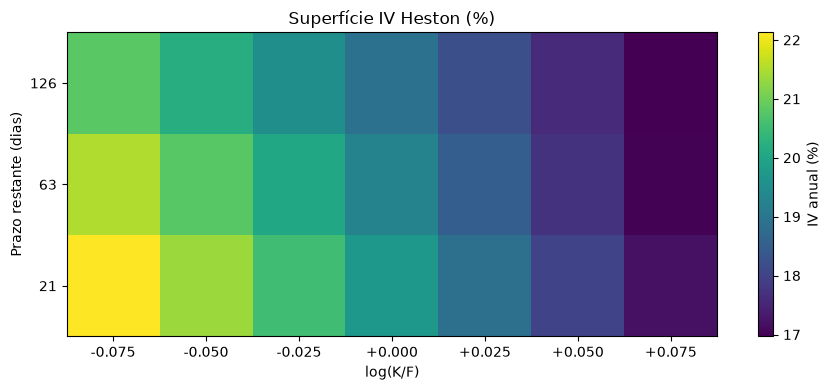

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(surface.implied_volatility * 100, origin="lower", aspect="auto")
ax.set_xticks(range(len(log_moneyness)), [f"{k:+.3f}" for k in log_moneyness])
ax.set_yticks(range(len(tenors)), tenors)
ax.set(xlabel="log(K/F)", ylabel="Prazo restante (dias)", title="Superfície IV Heston (%)")
fig.colorbar(im, ax=ax, label="IV anual (%)")
plt.tight_layout()
plt.show()

### 4.3. `build_volatility_lookup()` e `.evaluate()` — IV ao longo do tempo

Para evitar recalcular Heston em cada instante de cada trajetória, pré-calculamos a superfície para alguns valores de variância. Depois `evaluate(variance)` interpola **somente no eixo da variância**. A tabela tem tenores constantes (por exemplo, sempre 63 dias restantes), e **não** representa o envelhecimento de uma opção específica.

Nesta demo usaremos poucos nós para ser rápido. O interpolador **não extrapola**: se $v$ estiver fora do intervalo, a função retorna erro.

In [20]:
lookup = build_volatility_lookup(
    params_q, market_q,
    maturities_days=[21, 63, 126],
    log_moneyness=[-0.06, -0.03, 0.0, 0.03, 0.06],
    variance_nodes=[0.0, 0.01, 0.03, 0.04, 0.08, 0.16, 0.32, 0.60],
)
print("Tabela: (variâncias, prazos, moneyness) =", lookup.implied_volatility.shape)
iv_over_time = lookup.evaluate(daily_paths.variance[:1])
print("IV dinâmica: (caminhos, datas, prazos, moneyness) =", iv_over_time.shape)

Tabela: (variâncias, prazos, moneyness) = (8, 3, 5)
IV dinâmica: (caminhos, datas, prazos, moneyness) = (1, 64, 3, 5)


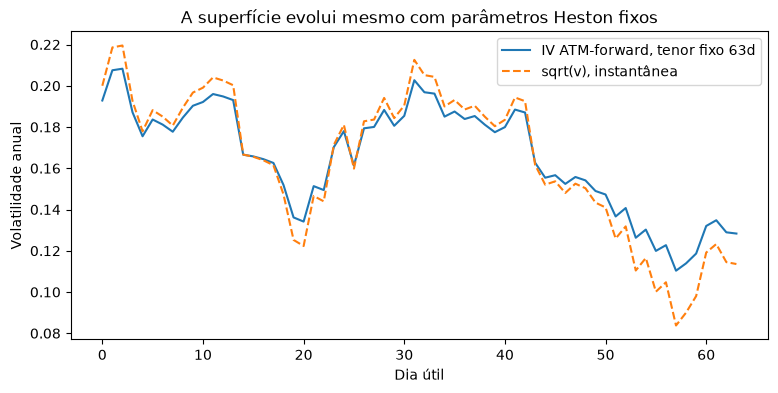

In [21]:
iv_atm_63 = iv_over_time[0, :, 1, 2]  # 63 dias e log(K/F)=0
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, iv_atm_63, label="IV ATM-forward, tenor fixo 63d")
ax.plot(days, np.sqrt(daily_paths.variance[0]), "--", label="sqrt(v), instantânea")
ax.set(xlabel="Dia útil", ylabel="Volatilidade anual",
       title="A superfície evolui mesmo com parâmetros Heston fixos")
ax.legend()
plt.show()

**Uma verificação útil:** a interpolação em variância introduz erro. Podemos compará-la com um cálculo de IV **direto** de um único estado, para a mesma coordenada ATM-forward e o mesmo prazo restante.

In [22]:
day_check = 20
current_s = float(daily_paths.spot[0, day_check])
current_v = float(daily_paths.variance[0, day_check])
direct_surface = heston_volatility_surface(
    params_q, market_q, maturities_days=[63], log_moneyness=[0.0],
    spot=current_s, variance=current_v,
)
print("IV direta:", f"{direct_surface.implied_volatility[0,0]:.5%}")
print("IV interpolada:", f"{iv_atm_63[day_check]:.5%}")
print("Erro absoluto:", abs(direct_surface.implied_volatility[0,0] - iv_atm_63[day_check]))

IV direta: 13.43529%
IV interpolada: 13.41452%
Erro absoluto: 0.00020772938427499055


## 5. `hedging.py` — valor diário, caixa e posições

### 5.1. `value_book_paths()` — marcação a mercado (*mark-to-market*)

**Entrada:** uma carteira, trajetórias sob P e precificador parametrizado sob Q. **Saída:** valores e sensibilidades dos contratos **que continuam vivos** e pagamentos dos que vencem em cada dia.

No dia em que a call vence, seu valor de mercado **ex-liquidação** passa a zero. Se houver pagamento, ele vai ao caixa. Assim, não contamos o mesmo dinheiro duas vezes.

In [23]:
marked = value_book_paths(
    book, daily_paths, params_q, market_q,
    trading_days_per_year=DAYS_PER_YEAR,
)
print("Valor diário shape:", marked.value.shape)
print("Delta diário shape:", marked.delta.shape)
for t in [0, 21, 63]:
    print(f"Dia {t:2d}: valor vivo={marked.value[0,t]:+9.4f}  "
          f"pagamento={marked.settlements[0,t]:+9.4f}  "
          f"delta={marked.delta[0,t]:+8.4f}")
print("Pagamentos conferem com portfolio.py?", np.allclose(marked.settlements, cashflows))

Valor diário shape: (12, 64)
Delta diário shape: (12, 64)
Dia  0: valor vivo=  +4.0045  pagamento=  +0.0000  delta= +1.3947
Dia 21: valor vivo=  -0.1800  pagamento= +12.4904  delta= +0.0366
Dia 63: valor vivo=  +0.0000  pagamento=  +0.0000  delta= +0.0000
Pagamentos conferem com portfolio.py? True


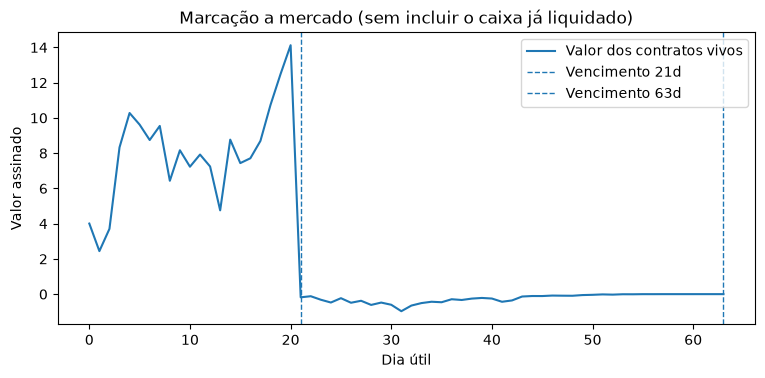

In [24]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(days, marked.value[0], label="Valor dos contratos vivos")
for maturity in [21, 63]:
    ax.axvline(maturity, ls="--", lw=1, label=f"Vencimento {maturity}d")
ax.set(xlabel="Dia útil", ylabel="Valor assinado",
       title="Marcação a mercado (sem incluir o caixa já liquidado)")
ax.legend()
plt.show()

### 5.2. `simulate_hedge()` — negociação do subjacente

A riqueza marcada a mercado é

$$W_t=\text{caixa}_t + h_t S_t + \text{valor dos contratos vivos}_t.$$

O código mantém um saldo de caixa que recebe/paga juros, liquida opções, compra ou vende ações e paga custos. O dinheiro inicial é `-valor_inicial_da_carteira`, de forma que a riqueza começa em zero **antes dos custos de negociação**. Com esse sinal convencionado, a posição delta-neutra em ações é aproximadamente $h_t=-\Delta_{\mathcal B,t}$.

Abaixo comparamos quatro políticas **já implementadas**, sem aprendizado por reforço. A banda fixa negocia até a **borda** da banda quando a posição sai dela.

In [25]:
hedge_cfg = config["hedging"]
strategies = {
    "Sem hedge": "no_hedge",
    "Delta diário": "delta_daily",
    "Delta 21d": "delta_periodic",
    "Banda fixa": "delta_band",
}
results = {}
for name, strategy in strategies.items():
    results[name] = simulate_hedge(
        daily_paths, marked, market_p, strategy=strategy,
        proportional_cost=hedge_cfg["proportional_cost"],
        fixed_cost=hedge_cfg["fixed_cost"],
        band_width=hedge_cfg["band_width"],
        rebalance_every=hedge_cfg["rebalance_every"],
        min_trade=hedge_cfg["min_trade"],
        trading_days_per_year=DAYS_PER_YEAR,
    )

for name, r in results.items():
    print(f"{name:13s} | P&L médio: {r.terminal_pnl.mean():+8.3f} "
          f"| custos: {r.transaction_cost.mean():7.3f} "
          f"| nº trades: {r.trades.mean():5.2f}")

Sem hedge     | P&L médio:   +1.347 | custos:   0.000 | nº trades:  0.00
Delta diário  | P&L médio:  -19.121 | custos:  18.922 | nº trades: 36.67
Delta 21d     | P&L médio:   -3.092 | custos:   2.292 | nº trades:  4.00
Banda fixa    | P&L médio:   -8.613 | custos:   7.200 | nº trades: 13.83


**Interpretando as posições:** a linha tracejada é o alvo $-\Delta$. A política delta diária o persegue quase todos os dias; a banda tolera desvios para economizar transações. O filtro `min_trade` pode impedir negócios pequenos. No último dia, as posições devem ser encerradas independentemente desse filtro (correção da auditoria anterior).

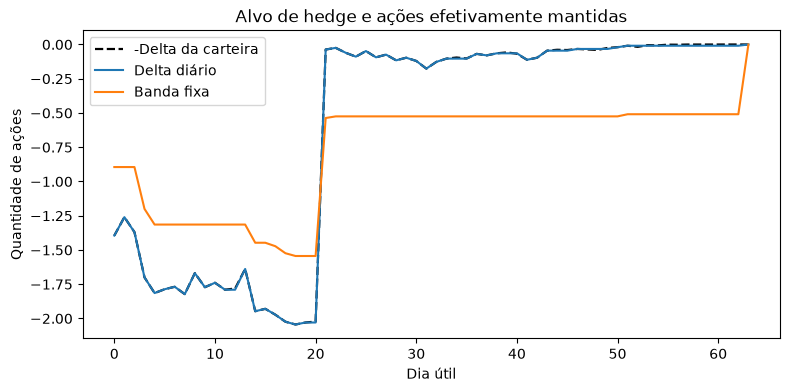

Posições finais zeradas? True


In [26]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(days, -marked.delta[0], "k--", lw=1.6, label="-Delta da carteira")
for name in ["Delta diário", "Banda fixa"]:
    ax.plot(days, results[name].position[0], label=name)
ax.set(xlabel="Dia útil", ylabel="Quantidade de ações",
       title="Alvo de hedge e ações efetivamente mantidas")
ax.legend()
plt.show()
print("Posições finais zeradas?", all(
    np.allclose(r.position[:, -1], 0) for r in results.values()
))

### 5.3. Riqueza e custos

Um hedge pode reduzir exposição ao risco e ainda assim piorar o P&L líquido porque **rebalancear custa dinheiro**. Veja o resultado de um caminho individual e os custos médios da mini-amostra.

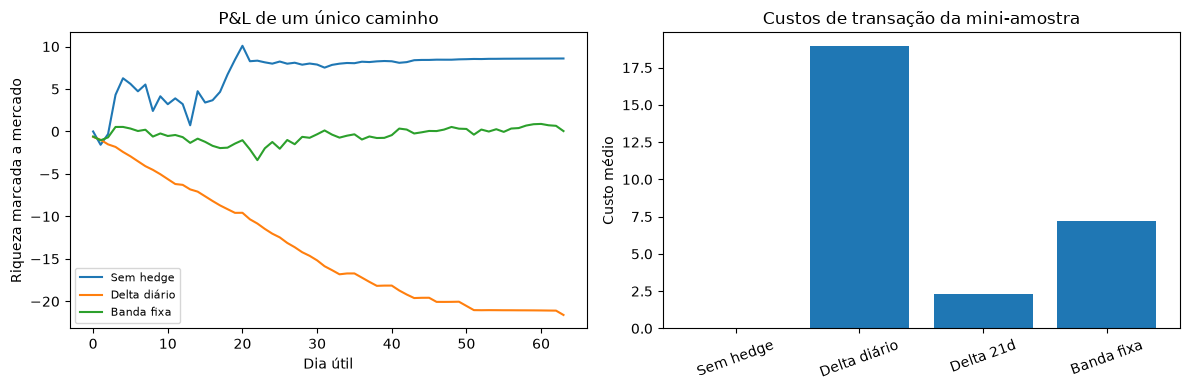

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name in ["Sem hedge", "Delta diário", "Banda fixa"]:
    axs[0].plot(days, results[name].wealth[0], label=name)
axs[0].set(xlabel="Dia útil", ylabel="Riqueza marcada a mercado",
           title="P&L de um único caminho")
axs[0].legend(fontsize=8)
axs[1].bar(list(results), [v.transaction_cost.mean() for v in results.values()])
axs[1].set(ylabel="Custo médio", title="Custos de transação da mini-amostra")
axs[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 5.4. `summarize_hedge()` — métricas financeiras

A função retorna P&L médio, perdas médias, quantil de 95% das perdas, CVaR95, custos, número de negócios e turnover.

**Convenção:** perda é `-P&L`; perdas positivas significam prejuízo. **Importante:** com apenas 12 trajetórias, Q95 e CVaR95 são altamente instáveis. Aqui exibimos o retorno da função para conhecer a interface — **não** para ranquear estratégias cientificamente.

In [28]:
example_summary = summarize_hedge(results["Banda fixa"])
for metric, value in example_summary.items():
    print(f"{metric:24s}: {value:12.5f}")

mean_pnl                :     -8.61340
mean_loss               :      8.61340
q95_loss                :     19.88513
cvar95_loss             :     19.88513
mean_transaction_cost   :      7.19979
mean_turnover           :      2.75476
mean_trades             :     13.83333


### 5.5. Checagem independente: P&L sem hedge

Em uma carteira sem negociação do subjacente, o caixa inicial é $-V_0$ e recebe os pagamentos dos contratos no vencimento. Assim, se todos os contratos vencerem antes do fim, podemos calcular o resultado terminal de outra maneira:

$$W_T=-V_0e^{rT}+\sum_{t=1}^{T}C_t e^{r(T-t)},$$

onde $C_t$ é o fluxo assinado de `expiry_cashflows` e os prazos da expressão são medidos em anos. Essa conferência é útil para entender o **motivo** da contabilidade, não para substituí-la.

In [29]:
dt = 1 / DAYS_PER_YEAR
r = market_p.risk_free_rate
terminal_day = N_STEPS
independent_pnl = (
    -marked.value[:, 0] * np.exp(r * terminal_day * dt)
    + np.sum(marked.settlements * np.exp(r * (terminal_day-days) * dt), axis=1)
)
difference = independent_pnl - results["Sem hedge"].terminal_pnl
print("Maior discrepância:", float(np.max(np.abs(difference))))
assert np.allclose(independent_pnl, results["Sem hedge"].terminal_pnl, atol=1e-9)

Maior discrepância: 4.263256414560601e-14


## 6. Os scripts de experimentos e os próximos passos

Agora você conhece as **funções reutilizáveis**. Os outros dois arquivos da raiz são **pontos de entrada**, e não novos modelos financeiros:

- `simulate.py`: lê `config.json`, gera trajetórias, carteiras, pagamentos e superfícies IV, e salva os arquivos em `results/simulations/`.
- `evaluate.py`: organiza os cenários P, valores e sensibilidades Q e executa os baselines; salva os resultados em `results/hedging/`.

Para experimentá-los, use um terminal na raiz do projeto (após ativar `.venv`):

```bash
python simulate.py --n-paths 100 --n-books 4
python evaluate.py --n-paths 32 --n-books 2
python -m pytest -q
```

**Eles salvam resultados; este notebook privilegia chamadas diretas e gráficos na tela.** O notebook não escreve arquivos automaticamente.

### Três experiências para você fazer nas próprias células

1. **Simulação:** altere `params_p.rho` e observe o relacionamento entre preço e variância. Lembre-se de recriar `HestonParams` (é um `dataclass` imutável).
2. **Carteira:** altere a quantidade ou o strike da call e compare pagamentos, valor inicial, delta e posição de hedge.
3. **Fricção:** altere `band_width` e `fixed_cost` na chamada de `simulate_hedge` e observe a frequência de transação e o resultado líquido.

> Em uma pesquisa formal ainda teremos de validar erros numéricos em regiões extremas, calibrar a relação P/Q e usar **muito mais caminhos e sementes**. Este notebook ensina **o que o código já faz**, não prova que um método é superior ou que uma política RL está pronta.

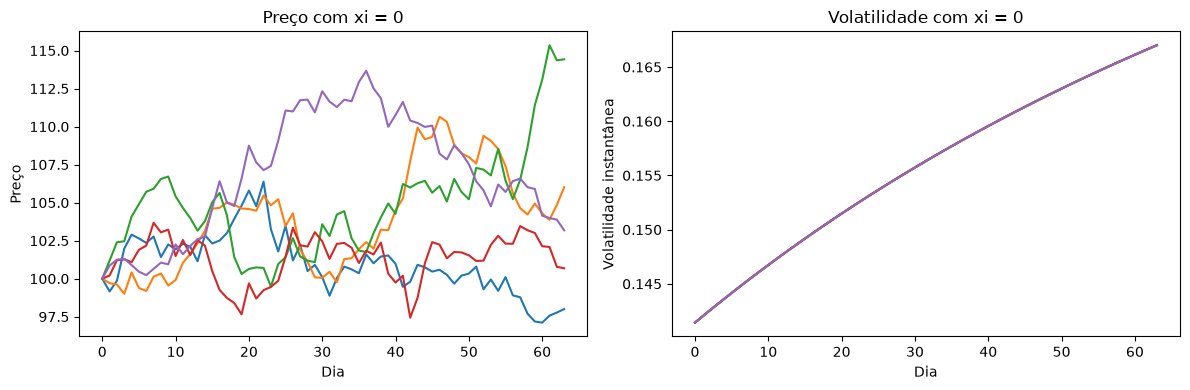

In [31]:
params_sem_volvol = HestonParams(
    kappa=2.0,
    theta=0.04,
    xi=0.0,
    rho=-0.70,
    v0=0.02,
)

paths_sem_volvol = simulate_heston(
    params_sem_volvol,
    market_p,
    n_paths=12,
    n_steps=63,
    seed=123,
)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

for i in range(5):
    axs[0].plot(paths_sem_volvol.spot[i])
    axs[1].plot(np.sqrt(paths_sem_volvol.variance[i]))

axs[0].set(
    title="Preço com xi = 0",
    xlabel="Dia",
    ylabel="Preço"
)

axs[1].set(
    title="Volatilidade com xi = 0",
    xlabel="Dia",
    ylabel="Volatilidade instantânea"
)

plt.tight_layout()
plt.show()